# 02 · Entrenamiento, calibración y exportación

Entrena la red, la calibra con la partición de validación y exporta en `models/` el modelo, el preprocesador, el calibrador, las variables y la Cartera puntuada. Toda la lógica vive en `src/` (ADR-0001).

In [1]:
import os, subprocess, sys
from pathlib import Path

# Rama que se entrena en Colab. Mientras el slice no esté en main, usa su rama
# (tiene que estar publicada en GitHub con git push).
BRANCH = "vs-003-evaluar-aceptar-rechazar"
REPO_URL = "https://github.com/Emmanuel2503/deep-retention.git"


def git(*args):
    done = subprocess.run(["git", *args], capture_output=True, text=True)
    if done.returncode != 0:
        raise RuntimeError(f"git {' '.join(args)} falló:\n{done.stderr.strip()}")


if "google.colab" in sys.modules:
    repo = Path("/content/deep-retention")
    try:
        if not repo.exists():
            git("clone", "--branch", BRANCH, REPO_URL, str(repo))
        else:
            # Una sesión anterior dejó el clon: se lleva a la última versión de BRANCH.
            # El clon de Colab es desechable: se descartan sus cambios locales (por
            # ejemplo, los models/ de un entrenamiento anterior). Descarga antes los
            # artefactos que quieras conservar.
            git("-C", str(repo), "fetch", "origin", f"+refs/heads/{BRANCH}:refs/remotes/origin/{BRANCH}")
            git("-C", str(repo), "checkout", "--force", "-B", BRANCH, f"origin/{BRANCH}")
    except RuntimeError as error:
        raise RuntimeError(
            f"No se pudo obtener la rama {BRANCH!r} de {REPO_URL}. "
            "Comprueba que la rama esté publicada en GitHub (git push -u origin <rama>).\n"
            f"{error}"
        ) from error
    %cd {repo}
    !git log -1 --oneline
    %pip install -q -r requirements.txt
elif Path.cwd().name == "notebooks":
    %cd ..

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

/content/deep-retention
274658d (HEAD -> vs-003-evaluar-aceptar-rechazar, origin/vs-003-evaluar-aceptar-rechazar) fix: sincronizar el clon de Colab con la rama aunque tenga artefactos locales (VS-003)


## Versiones del entorno

Se fijan en `requirements.txt` con `==` (SRS/TR-02). Colab debe usar Python 3.12 o 3.13 (`>=3.12, <3.14`).

In [2]:
import platform
from importlib.metadata import version

print("python", platform.python_version())
for lib in ["tensorflow", "scikit-learn", "joblib", "numpy", "pandas", "matplotlib"]:
    print(f"{lib}=={version(lib)}")

python 3.13.18
tensorflow==2.21.0
scikit-learn==1.6.1
joblib==1.6.0
numpy==2.4.6
pandas==2.2.3
matplotlib==3.11.2


## Particiones reproducibles (AC-01)

In [3]:
from src.preprocessing import TARGET, load_dataset, split_data

df = load_dataset()
run_a = split_data(df)
run_b = split_data(df)
for name, a, b in zip(["train", "val", "test"], run_a, run_b):
    same = set(a["CustomerId"]) == set(b["CustomerId"])
    print(name, len(a), "abandono", round(a[TARGET].mean(), 4), "mismos clientes:", same)

train 7000 abandono 0.2039 mismos clientes: True
val 1500 abandono 0.204 mismos clientes: True
test 1500 abandono 0.2033 mismos clientes: True


## Entrenamiento

In [4]:
from src.train import run_training

result = run_training()
print("mejor época:", result.best_epoch, "· detenido en:", result.stopped_epoch)

Epoch 1/200
110/110 - 2s - 16ms/step - loss: 0.6856 - val_loss: 0.6615
Epoch 2/200
110/110 - 0s - 3ms/step - loss: 0.6093 - val_loss: 0.6206
Epoch 3/200
110/110 - 0s - 3ms/step - loss: 0.5785 - val_loss: 0.5786
Epoch 4/200
110/110 - 0s - 2ms/step - loss: 0.5619 - val_loss: 0.5618
Epoch 5/200
110/110 - 0s - 3ms/step - loss: 0.5400 - val_loss: 0.5415
Epoch 6/200
110/110 - 0s - 3ms/step - loss: 0.5343 - val_loss: 0.5270
Epoch 7/200
110/110 - 0s - 3ms/step - loss: 0.5178 - val_loss: 0.5225
Epoch 8/200
110/110 - 0s - 3ms/step - loss: 0.5133 - val_loss: 0.5082
Epoch 9/200
110/110 - 0s - 4ms/step - loss: 0.5017 - val_loss: 0.5096
Epoch 10/200
110/110 - 1s - 5ms/step - loss: 0.5051 - val_loss: 0.4989
Epoch 11/200
110/110 - 0s - 3ms/step - loss: 0.4954 - val_loss: 0.4905
Epoch 12/200
110/110 - 0s - 3ms/step - loss: 0.4810 - val_loss: 0.4977
Epoch 13/200
110/110 - 0s - 2ms/step - loss: 0.4802 - val_loss: 0.5027
Epoch 14/200
110/110 - 0s - 2ms/step - loss: 0.4786 - val_loss: 0.4907
Epoch 15/200
1

## Comprobación del early stopping (AC-02)

In [5]:
from src.config import MODELS_DIR
from src.inference import ChurnPredictor
from src.model import PATIENCE
from src.preprocessing import TARGET

predictor = ChurnPredictor.load()
val = df.loc[df["CustomerId"].isin(result.split_ids["val"])]
val_loss_saved = float(
    predictor.model.evaluate(predictor.transform(val), val[TARGET], verbose=0)
)
val_loss_best = result.val_loss[result.best_epoch]
print("PATIENCE:", PATIENCE)
print("stopped_epoch - best_epoch:", result.stopped_epoch - result.best_epoch)
print(f"val_loss del historial en best_epoch: {val_loss_best:.6f}")
print(f"val_loss del modelo guardado:          {val_loss_saved:.6f}")
print("diferencia:", abs(val_loss_best - val_loss_saved))

PATIENCE: 12
stopped_epoch - best_epoch: 12
val_loss del historial en best_epoch: 0.470365
val_loss del modelo guardado:          0.470365
diferencia: 0.0


## Predicción sin reentrenar (AC-03)

In [6]:
import pandas as pd

p = predictor.predict(df)
print(len(p), "clientes · min", p.min(), "· max", p.max())
pd.read_csv(MODELS_DIR / "portfolio_scored.csv").head()

10000 clientes · min 0.0008661989474610396 · max 0.9999982739856408


,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Satisfaction Score,Card Type,Point Earned,Exited,split,p_raw,p_churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,2,DIAMOND,464,1,train,0.780185,0.427837
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,3,DIAMOND,456,0,train,0.654501,0.296513
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,3,DIAMOND,377,1,train,0.998998,0.992290
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,5,GOLD,350,0,test,0.148184,0.045469
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,5,GOLD,425,0,test,0.358238,0.121356


## Evaluación con los Clientes de prueba (VS-003)

Calcula ROC-AUC, PR-AUC y Brier antes y después de calibrar solo con los Clientes de prueba, guarda `models/metrics.json` y la curva de fiabilidad. Si `accepted` es `False`, no se versionan los artefactos: corrige el entrenamiento y repítelo.

{
  "n_test": 1500,
  "roc_auc": 0.88247753618218,
  "pr_auc": 0.7362691485272863,
  "brier_raw": 0.1424494108881129,
  "brier_calibrated": 0.09564439102255498,
  "accepted": true
}
n_test es 1,500: True
Modelo ACEPTADO


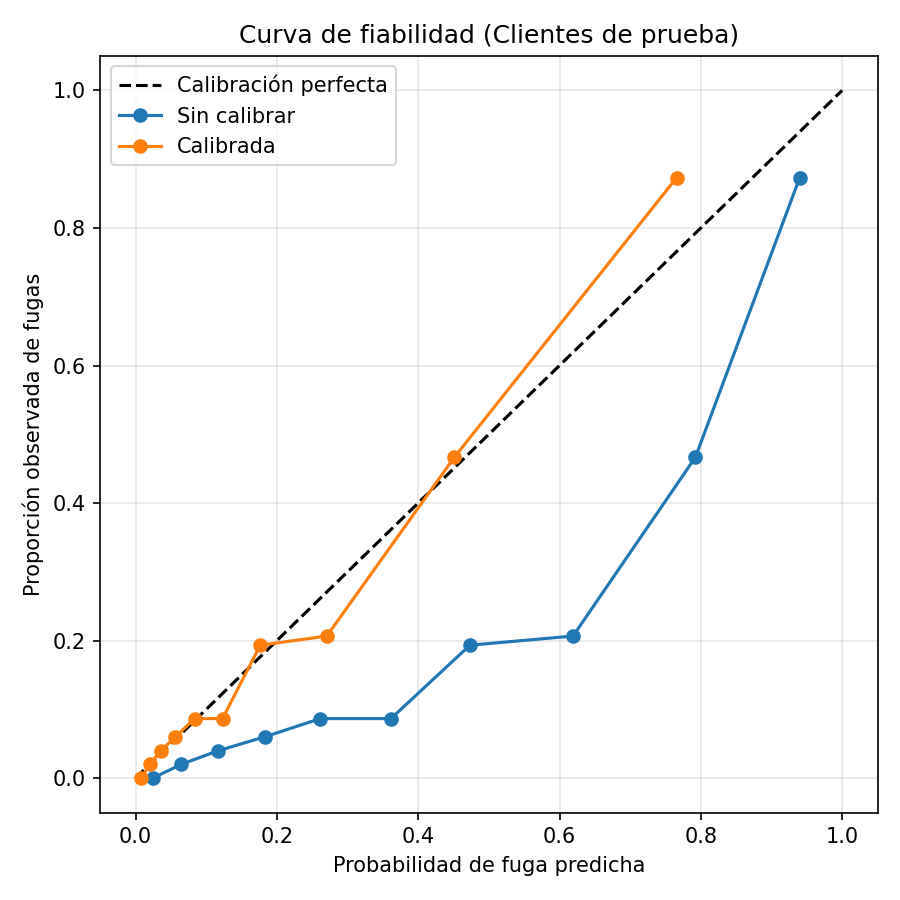

In [7]:
import json
from IPython.display import Image, display

from src.evaluate import reliability_path, run_evaluation

metrics = run_evaluation()
print(json.dumps(metrics, indent=2))
print("n_test es 1,500:", metrics["n_test"] == 1500)
print("Modelo ACEPTADO" if metrics["accepted"] else "Modelo NO ACEPTADO: no versiones los artefactos; corrige el entrenamiento y repítelo")
display(Image(filename=str(reliability_path())))